# Program 18: the relapse guard

**What:** add the penalty λ·Σ‖U_cᵀh(x)‖² to every training step after a class is forgotten.

**How:** keep a list of stored U_c matrices. In the DER++ loss, compute features for the current batch, project them onto each U_c, and add the squared norm times λ. Start with λ in {0.01, 0.1, 1}.

**Why:** this is the main contribution: it directly blocks the backward-transfer route to relapse found in program 15.

**Understanding note:** the guard tells the network, "learn the new task, but don't use the forgotten class's feature directions to do it."

**Done when:** probe-level relapse drops clearly compared with program 17, while RA stays within a few points.

## Where this fits (for a first-time reader)

Program 17's simple fixes handle the **output**: the head can't answer a forgotten class anymore. What's left is the **features**: the body may still separate the forgotten classes, and later learning (especially of similar classes) may make them even more separable. That's what the guard targets.

**The guard, step by step:**
1. At a `U` request, *before* unlearning, record the forgotten item's **signature** U_c: 5 directions of the 512-dim feature space (program 16).
2. From then on, in every training batch of every later task, compute how much of the batch's feature variation lies in those directions, and add it to the loss times λ:

$$\mathcal{L} = \mathcal{L}_{\text{DER++}} + \lambda \sum_{c \in \text{forgotten}} \frac{\lVert U_c^\top (h - \bar h) \rVert^2}{\lVert h - \bar h \rVert^2}$$

**Two changes from the roadmap's formula, both from program 16's findings:**
- **Centered and normalized.** h̄ is the batch's mean feature. After ReLU all features share a big common direction, so the raw ‖U_cᵀh‖² mostly measures that, not the class. Dividing by the total ‖h − h̄‖² makes the guard a **share** between 0 and 1 (the fraction of the batch's feature variation inside the forgotten directions), so λ means the same thing in every network. That's why we test λ ∈ {0.1, 1, 10} instead of {0.01, 0.1, 1}.
- **A class-specific signature.** Program 16's plain PCA signature overlapped heavily with kept classes (0.78 with kangaroo), so guarding it would also hurt them. The `specific` signature uses *contrastive PCA* (Abid et al., 2018): the directions where the forgotten class has much **more** feature energy than the kept classes (top eigenvectors of C_forget − C_retain).

**Two experiments:**
- **Part A, the stream** (`task15_seed0`, as programs 12–17): the simple fixes + the guard, for λ = 0.1, 1, 10. Compared with program 17.
- **Part B, wolf** (program 15's controlled setting): learn task A → forget wolf → learn the **similar** task (fox, lion, tiger, …), the backward-transfer route. 3 seeds, for: simple fixes only, + guard with the plain signature, + guard with the specific signature.

## 1. Setup

**Time:** Part A about 15 minutes per λ (45 minutes), Part B about 2.5 minutes per run (9 runs, about 25 minutes). Saved runs with the same config are loaded instead.

In [1]:
import gc, json, sys, time
from pathlib import Path

ROOT = Path.cwd() if (Path.cwd() / "common").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))  # lets us import common/

# Reload the shared code, so edits to common/ are picked up even without restarting the kernel.
import importlib
import common.utils, common.data, common.models, common.derpp, common.badteacher, common.features, common.metrics, common.stream, common.clu
for module in (common.utils, common.data, common.models, common.derpp, common.badteacher, common.features, common.metrics, common.stream, common.clu):
    importlib.reload(module)

import matplotlib.pyplot as plt
import numpy as np

from common.clu import load_result, make_config, run_or_load
from common.data import SplitCIFAR100
from common.metrics import all_metrics, item_view
from common.utils import RESULTS_DIR, log_run

# Program 14's retrain model: probe accuracy on each task when the task was NEVER learned (the target).
RETRAIN_PROBE = None
for line in (RESULTS_DIR / "runs.jsonl").read_text().splitlines():
    entry = json.loads(line)
    if entry["program"] == "14_feature_probe":
        RETRAIN_PROBE = np.array(entry["results"]["probe"]["retrain"])

def metrics_row(res, kind="til"):
    s = res["summary"][kind]
    return s["RA"], s["FA"], s["Spill"], s["Relapse"]


def show_table(runs, retrain_probe=None):
    """runs: name -> result dict. Prints the four metrics and the probe numbers on forgotten items."""
    print(f"{'run':>28} | {'RA':>6} {'FA':>6} {'Spill':>6} {'Relapse':>7} | {'RA cil':>6} {'FA cil':>6} | "
          f"{'probe: before':>13} {'after U':>8} {'end':>6} {'peak rise':>9}")
    for name, res in runs.items():
        ra, fa, sp, rel = metrics_row(res, "til")
        rac, fac, _, _ = metrics_row(res, "cil")
        p = res["summary"].get("probe")
        ptxt = (f"{p['before']*100:12.1f}% {p['after_U']*100:7.1f}% {p['end']*100:5.1f}% {p['peak_rise']*100:+8.1f}"
                if p else f"{'-':>13} {'-':>8} {'-':>6} {'-':>9}")
        print(f"{name:>28} | {ra*100:5.1f}% {fa*100:5.1f}% {sp*100:6.1f} {rel*100:7.1f} | {rac*100:5.1f}% {fac*100:5.1f}% | {ptxt}")
    if retrain_probe is not None:
        print(f"\nretrain model (program 14), probe on the same forgotten tasks: {retrain_probe*100:.1f}%  (the target)")
    print("RA/FA/Spill/Relapse: task-IL (chance 10%); 'cil' = class-IL. Probe: 10-way on each forgotten task's features.")


def plot_forgotten(runs, title, file, show_retrain=True):
    """Head task-IL accuracy and feature probe of the forgotten items after every request."""
    import warnings
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
    for name, res in runs.items():
        acc, learned, forgotten, rows = item_view(res, "til")
        head = [np.nanmean(acc[r, forgotten[r]]) * 100 if forgotten[r].any() else np.nan for r in range(len(acc))]
        line, = axes[0].plot(head, marker="o", ms=3, label=name)
        if "probe" in res:
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                axes[1].plot(np.nanmean(res["probe"], axis=1) * 100, marker="o", ms=3, color=line.get_color(), label=name)
    labels = [str(s) for s in next(iter(runs.values()))["requests"]]
    for ax in axes:
        ax.set_xticks(range(len(labels)), labels, rotation=45, fontsize=8)
    axes[0].axhline(10, color="gray", ls="--", lw=1, label="chance")
    axes[0].set(title="Head: task-IL accuracy of forgotten tasks (average, %)", ylabel="accuracy (%)", ylim=(0, 100))
    axes[1].set(title="Features: probe accuracy of forgotten tasks (average, %)", ylabel="probe accuracy (%)")
    if show_retrain and RETRAIN_PROBE is not None:
        axes[1].axhline(RETRAIN_PROBE[[int(s[1:]) for s in labels if s[0] == "U"]].mean() * 100,
                        color="green", ls=":", lw=1.5, label="retrain (target)")
    for ax in axes:
        ax.legend(fontsize=8)
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(RESULTS_DIR / file, dpi=120)
    plt.show()

WOLF_TASKS = {
    "A": ["wolf", "camel", "cattle", "chimpanzee", "elephant", "kangaroo", "bus", "bicycle", "orchid", "apple"],
    "similar": ["bear", "leopard", "lion", "tiger", "fox", "porcupine", "possum", "raccoon", "skunk", "otter"],
}


def run_wolf(prefix, seeds, data, **overrides):
    """L task A -> U wolf (with the simple fixes) -> L the similar task, once per seed."""
    lab = {n: data.class_names.index(n) for n in data.class_names}
    tasks = {0: [lab[n] for n in WOLF_TASKS["A"]], 1: [lab[n] for n in WOLF_TASKS["similar"]]}
    out = {}
    for seed in seeds:
        cfg = make_config(name=f"{prefix}_s{seed}", seed=seed, head_reset=True, mask_forgotten_logits=True, **overrides)
        print(f"--- {cfg['name']}")
        out[seed] = run_or_load(cfg, data, requests=[("L", 0), ("U", lab["wolf"]), ("L", 1)], tasks=tasks, level="class")
    return out


def wolf_numbers(res):
    """Probe of wolf (wolf vs the other task-A classes, chance 50%) before U / after U / at the end, and the
    task-IL accuracy of all kept classes at the end."""
    b, a, e = list(res["summary"]["probe"]["per_item"].values())[0]
    kept = res["learned"][-1] & ~res["forgotten"][-1]
    return {"before": b, "after_U": a, "end": e, "rise": e - a, "kept_acc": float(np.nanmean(res["acc_til"][-1][kept]))}


def show_wolf(groups):
    """groups: name -> {seed: result}. Mean ± spread over seeds."""
    print(f"{'config':>26} | {'probe before U':>14} {'after U':>12} {'end':>12} {'rise':>12} | {'kept acc (end)':>14}")
    table = {}
    for name, per_seed in groups.items():
        nums = [wolf_numbers(r) for r in per_seed.values()]
        table[name] = {k: (np.mean([n[k] for n in nums]), np.std([n[k] for n in nums])) for k in nums[0]}
        t = table[name]
        print(f"{name:>26} | " + " ".join(f"{t[k][0]*100:6.1f} ± {t[k][1]*100:3.1f}" if k != "rise" else
                                         f"{t[k][0]*100:+6.1f} ± {t[k][1]*100:3.1f}"
                                         for k in ("before", "after_U", "end", "rise")) +
              f" | {t['kept_acc'][0]*100:7.1f} ± {t['kept_acc'][1]*100:3.1f}")
    print("probe: wolf vs the other 9 task-A classes on test features (chance 50%; a never-trained network gets ~72%)")
    return table

LAMBDAS = [0.1, 1.0, 10.0]
SEEDS = [0, 1, 2]
RUNS = {f"18_guard_l{lam:g}": make_config(name=f"18_guard_l{lam:g}", stream="task15_seed0", head_reset=True,
                                         mask_forgotten_logits=True, guard="penalty", guard_lambda=lam, signature="specific")
        for lam in LAMBDAS}
SETTINGS = {"lambdas": LAMBDAS, "seeds": SEEDS, "config": RUNS[f"18_guard_l1"]}

## 2. Part A: the guard on the stream

`guard share` in each `L` line is the average share of the batch's feature variation inside the forgotten directions. It should stay small when λ is large.

In [2]:
data = SplitCIFAR100(seed=0, batch_size=32, num_workers=2)
results = {}
for name, cfg in RUNS.items():
    print(f"===== {name}")
    results[name] = run_or_load(cfg, data)

===== 18_guard_l0.1


[  0] L5   kept  66.5%  train acc 65.1%  (76s)


[  1] L2   kept  72.2%  train acc 78.7%  (152s)


[  2] L3   kept  74.8%  train acc 74.0%  (227s)


[  3] L4   kept  75.7%  train acc 82.6%  (304s)


[  4] U5   kept  76.8%  forgot head   8.4%  probe  71.9%  forget imgs 5000 (494 in buffer), deleted 494  (332s)


... (38 outputs left out)

[ 11] L7   kept  78.2%  forgot head  12.1%  probe  76.8%  train acc 92.8%, guard share 0.006  (736s)


[ 12] L6   kept  79.3%  forgot head   8.8%  probe  75.8%  train acc 89.5%, guard share 0.003  (817s)


[ 13] L1   kept  80.4%  forgot head  12.4%  probe  76.6%  train acc 92.6%, guard share 0.003  (896s)


[ 14] U4   kept  76.2%  forgot head  12.0%  probe  76.2%  forget imgs 5000 (199 in buffer), deleted 199  (925s)


## 3. Part A: compared with program 17

Same columns as program 17. The guard should lower the probe on forgotten tasks (especially `end` and `peak rise`) while RA stays within a few points of program 17.

                         run |     RA     FA  Spill Relapse | RA cil FA cil | probe: before  after U    end peak rise
          17_badteacher_only |  77.1%  33.3%    8.1    21.1 |  54.9%   1.9% |         78.8%    76.5%  75.9%     +1.9
             17_simple_fixes |  76.9%  11.7%    7.9     2.7 |  54.0%   0.0% |         79.0%    77.5%  76.1%     +1.4
               18_guard_l0.1 |  76.3%  10.2%    9.4     2.3 |  55.3%   0.0% |         78.9%    78.1%  76.8%     +1.2
                 18_guard_l1 |  77.5%   9.9%    7.7     1.4 |  56.8%   0.0% |         78.5%    77.0%  75.4%     +1.2
                18_guard_l10 |  76.2%  12.0%    9.5     5.2 |  54.4%   0.0% |         78.9%    78.6%  76.2%     +0.6

retrain model (program 14), probe on the same forgotten tasks: 71.1%  (the target)
RA/FA/Spill/Relapse: task-IL (chance 10%); 'cil' = class-IL. Probe: 10-way on each forgotten task's features.


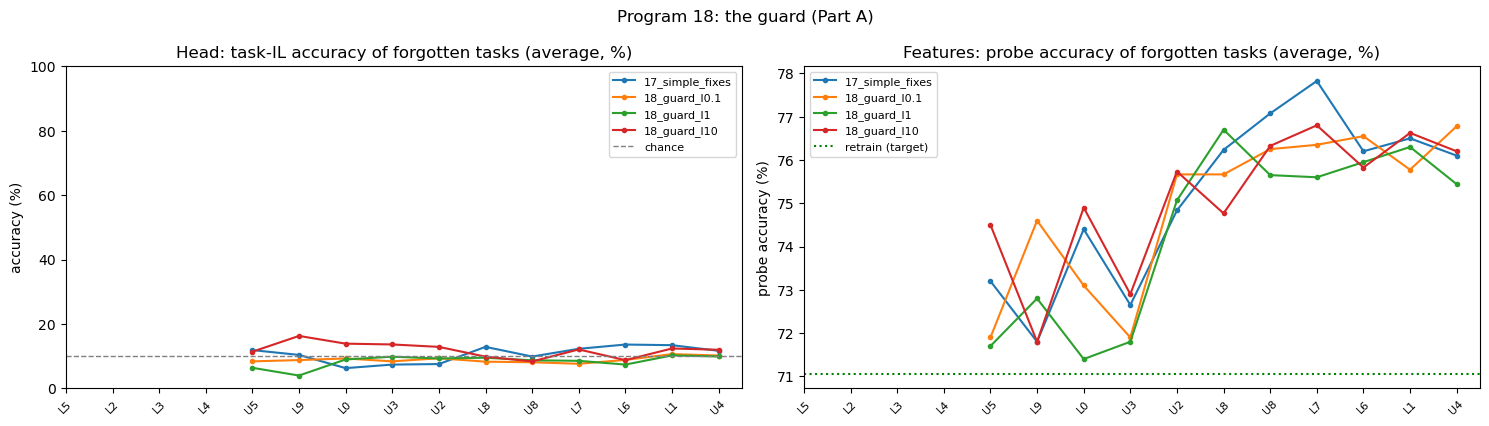

In [3]:
runs = {}
for name in ("17_badteacher_only", "17_simple_fixes"):
    r = load_result(name)
    if r is not None:
        runs[name] = r
runs.update(results)
forgotten_tasks = [int(s[1:]) for s in results[f"18_guard_l1"]["requests"] if str(s)[0] == "U"]
show_table(runs, RETRAIN_PROBE[forgotten_tasks].mean() if RETRAIN_PROBE is not None else None)
plot_forgotten({k: v for k, v in runs.items() if k != "17_badteacher_only"}, "Program 18: the guard (Part A)", "18_guard_stream.png")

## 4. Part B: wolf and the similar task

Each run: learn task A → `U wolf` (BadTeacher + head reset + purge + logit mask, plus the guard's signature) → learn the similar task, with or without the guard.

The probe is wolf vs the other 9 task-A classes on test features (chance 50%; a never-trained network already gets about 72%, program 15). **Rise** = end − after `U`: how much learning the similar task brought wolf back into the features. **Kept acc** = task-IL accuracy of all kept classes at the end, to check the guard doesn't hurt them.

In [4]:
wolf_groups = {
    "simple fixes (no guard)": run_wolf("18_wolf_fixes", SEEDS, data),
    "guard, plain signature": run_wolf("18_wolf_plain", SEEDS, data, guard="penalty", guard_lambda=1.0, signature="plain"),
    "guard, specific signature": run_wolf("18_wolf_specific", SEEDS, data, guard="penalty", guard_lambda=1.0, signature="specific"),
}
del data
gc.collect()

--- 18_wolf_fixes_s0


[  0] L0   kept  60.7%  train acc 64.4%  (75s)


[  1] U73  kept  65.2%  forgot head   0.0%  probe  91.0%  forget imgs 500 (203 in buffer), deleted 203  (102s)


[  2] L1   kept  63.1%  forgot head   0.0%  probe  88.5%  train acc 61.3%  (180s)


--- 18_wolf_fixes_s1


[  0] L0   kept  65.3%  train acc 64.7%  (76s)


... (27 outputs left out)

[  0] L0   kept  60.3%  train acc 66.1%  (76s)


[  1] U73  kept  61.4%  forgot head   0.0%  probe  89.5%  forget imgs 500 (198 in buffer), deleted 198  (103s)


[  2] L1   kept  64.0%  forgot head   0.0%  probe  84.5%  train acc 63.5%, guard share 0.010  (182s)


0

                    config | probe before U      after U          end         rise | kept acc (end)
   simple fixes (no guard) |   88.8 ± 1.6   90.0 ± 1.8   88.0 ± 0.7   -2.0 ± 1.1 |    63.9 ± 0.6
    guard, plain signature |   88.2 ± 1.6   89.8 ± 1.0   85.0 ± 0.4   -4.8 ± 0.6 |    63.0 ± 1.5
 guard, specific signature |   86.8 ± 0.2   89.3 ± 2.2   86.5 ± 2.5   -2.8 ± 1.5 |    63.4 ± 0.8
probe: wolf vs the other 9 task-A classes on test features (chance 50%; a never-trained network gets ~72%)


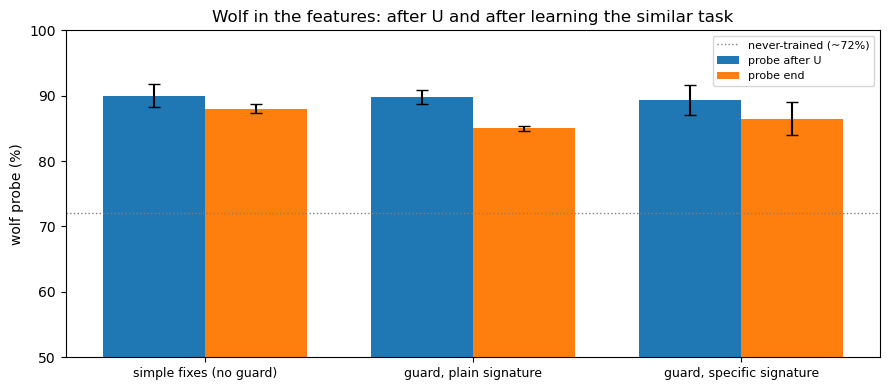

In [5]:
wolf_table = show_wolf(wolf_groups)

fig, ax = plt.subplots(figsize=(9, 4))
names = list(wolf_table)
for j, key in enumerate(["after_U", "end"]):
    ax.bar(np.arange(len(names)) + (j - 0.5) * 0.38, [wolf_table[n][key][0] * 100 for n in names], 0.38,
           yerr=[wolf_table[n][key][1] * 100 for n in names], capsize=4, label=f"probe {key.replace('_', ' ')}")
ax.axhline(72, color="gray", ls=":", lw=1, label="never-trained (~72%)")
ax.set_xticks(np.arange(len(names)), names, fontsize=9)
ax.set(ylabel="wolf probe (%)", ylim=(50, 100), title="Wolf in the features: after U and after learning the similar task")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(RESULTS_DIR / "18_guard_wolf.png", dpi=120)
plt.show()

## 5. Log the run

In [6]:
log_run("18_guard_loss", SETTINGS,
        {"stream": {name: res["summary"] for name, res in results.items()},
         "wolf": {name: {k: [round(v[0], 4), round(v[1], 4)] for k, v in t.items()} for name, t in wolf_table.items()}})
print("logged to", RESULTS_DIR / "runs.jsonl")

logged to /run/media/adarsh/AAE039EFE039C1FD/std/research/results/runs.jsonl


## Lab notebook

*Write one paragraph here: what you saw, and what surprised you.*

Questions to answer in it:
1. Part A: did any λ lower the probe on forgotten tasks compared with program 17? By how much, and what did it cost in RA and Spill?
2. Is the probe moving towards the retrain target, or below it? Below the target would mean the guard damages features more than "never learned" would.
3. Part B: with no guard, did learning the similar task raise wolf's probe (backward transfer)? Did the guard stop it?
4. Plain vs specific signature: which protects wolf better, and which keeps the other classes better?
5. The roadmap's done-when: "probe-level relapse drops clearly compared with program 17, while RA stays within a few points". Met or not?